
# Sparse current in the kernel of the scattering dual

Bound on the scattered power $\tfrac12 I^H R_0 I$ of a structure carved out of the copper 2:1 plate (`*_patch21ka1.txt`, $ka = 1$ at 2.45 GHz,
plane wave $E_0 = 1$ kV/m), in the RWG basis with $Z_\mathrm{mat} = Z_s L$ and the scattered voltage $x = V_\mathrm{sca} = -Z_0 I$ as the
variable, as in `nullSpaceMinField.ipynb`. The scattered-voltage Lagrangian has a better separated near-kernel than the current one
(`currentNullSpaceMinField.ipynb`).

The GCD Lagrangian $L^\star$ is (nearly) constant on $x = x_r + N y$, where $N$ is its near-kernel (eigenvalues below $\epsilon\,\lambda_\mathrm{max}$) and
$x_r = (1 - N N^H) x^\star$. Here $\epsilon = 10^{-4}$: the subspace changes the Lagrangian by about 0.5 %, far below the precision of the mesh, and
it is wide enough ($K \approx 160$ of 233) to switch off most basis functions. In the kernel the current is affine in $y$,
$$I(y) = -W (x_r + N y), \qquad r(y) = V - Z_\mathrm{tot} I(y) = V + Z_\mathrm{tot} W (x_r + N y),$$
and the kernel component is chosen to make the current structure-like, by iteratively reweighted least squares (IRLS). Every IRLS step is
a QCQP in $y$ with a positive definite quadratic objective and the global power constraints ($p = 1$, $p = j$, mapped by `projectorForm`).
Two objectives are compared:

1. **Sparsity**: $\min \sum_i \log(|I_i|^2 + \delta_I^2)$, i.e. IRLS on $\sum_i \alpha_i |I_i|^2$ with $\alpha_i = 1/(|I_i|^2 + \delta_I^2)$. It drives currents to zero,
   as a smoothed $\ell_0$ count.
2. **Complementarity**: $\min \sum_i \log(|I_i|^2 + \delta_I^2) + \log(|r_i|^2 + \delta_r^2)$, IRLS on $\sum_i \alpha_i |I_i|^2 + \beta_i |r_i|^2$ with
   $\beta_i = 1/(|r_i|^2 + \delta_r^2)$. A structure has either $I_i = 0$ (void) or $r_i = 0$ (metal, $d_i = 1$), so this is a smoothed count of the
   pointwise violations $|w_i| = |I_i|\,|r_i|$.

The smoothing $\delta$ is relative to the rms values of $I$ and $r$ at the GCD solution and decreases geometrically. A kernel of dimension $K$ can
zero at most about $K$ complex quantities, so the IRLS can only make the current as structure-like as the kernel allows.


In [1]:
import contextlib
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.linalg as la
import scipy.sparse as sp
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1" # copper 2:1 plate, ka = 1; omW and the mesh exist for this set only (exportOmWpatch21ka1.m)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum
eta_0 = np.sqrt(mu_0/epsilon_0) # free-space impedance

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance
print(f"Surface impedance: {Zs} Ω")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω


In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Zmat = Zs * Lmat # material impedance matrix (non-diagonal)
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix
Ldiag = np.diag(Lmat).copy() # diagonal of the lossy matrix

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W")

# reference: lossless resonant electric dipole, sigma_sca = 3 lambda^2 / (2 pi)
Pdip = 3*(c/frequency)**2/(2*np.pi) * E0**2/(2*eta_0)
print(f"resonant dipole scattered power: {Pdip:.4f} W")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W
resonant dipole scattered power: 9.4884 W


In [4]:
# mesh of the operators (exportOmWpatch21ka1.m): bf[n] = [T+, T-, edge node 1, edge node 2], 0 based
mesh = sio.loadmat(f"mesh_{matrixSet}.mat")
nodes, tria, bf = mesh["nodes"], mesh["triangles"], mesh["bf"]
edgeLen = np.linalg.norm(nodes[bf[:, 2]] - nodes[bf[:, 3]], axis=1)
e1, e2 = nodes[tria[:, 1]] - nodes[tria[:, 0]], nodes[tria[:, 2]] - nodes[tria[:, 0]]
triArea = 0.5*np.abs(e1[:, 0]*e2[:, 1] - e1[:, 1]*e2[:, 0])
triCent = nodes[tria].mean(axis=1)
freeNode = np.array([[np.setdiff1d(tria[t], bf[n, 2:])[0] for t in bf[n, :2]] for n in range(Ndes)]) # free vertices of T+, T-
print(f"{len(nodes)} nodes, {len(tria)} triangles, plate {np.ptp(nodes[:, 0])*1e3:.2f} x {np.ptp(nodes[:, 1])*1e3:.2f} mm, "
      f"Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error {np.max(np.abs(Ldiag/(5/(6*np.sqrt(3))*edgeLen**2) - 1)):.1e}")

def currentDensity(I):
    # RWG current density at the triangle centroids, J = I_n l_n rho / (2 A)
    J = np.zeros((len(tria), 2), dtype=complex)
    for s, sgn in [(0, 1), (1, -1)]:
        rho = sgn*(triCent[bf[:, s]] - nodes[freeNode[:, s]])
        np.add.at(J, bf[:, s], (I*edgeLen/(2*triArea[bf[:, s]]))[:, None]*rho)
    return J

def plotStructure(ax, keep, I, title=""):
    # metal triangles colored by |J| (log); removed RWG functions between metal triangles are slots (red), void triangles white
    metal = np.zeros(len(tria), dtype=bool)
    metal[bf[keep, :2].ravel()] = True
    J = np.linalg.norm(np.abs(currentDensity(I)), axis=1)
    pc = PolyCollection(nodes[tria[metal]], array=np.maximum(J[metal], 1e-3*J.max()), cmap='viridis',
                        norm=LogNorm(1e-3*J.max(), J.max()), edgecolors='none')
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(nodes[tria[~metal]], facecolors='white', edgecolors='0.85', linewidths=0.3))
    slot = ~keep & metal[bf[:, 0]] & metal[bf[:, 1]]
    ax.add_collection(LineCollection(nodes[bf[slot, 2:]], colors='r', linewidths=1.5))
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return pc

def plotDensity(ax, d, title=""):
    # inferred density on the RWG edges
    lc = LineCollection(nodes[bf[:, 2:]], array=np.log10(np.maximum(d, 1e-6)), cmap='viridis', linewidths=2.5)
    lc.set_clim(-6, 0)
    ax.add_collection(lc)
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return lc

def plotComplexDensity(axes, d, title=""):
    # complex density on the RWG edges: Re d (1 metal, 0 void) and Im d (0 for any structure), on a common symmetric scale
    dmax = np.quantile(np.abs(d), 0.99)
    for ax, part, name in [(axes[0], d.real, "Re d"), (axes[1], d.imag, "Im d")]:
        lc = LineCollection(nodes[bf[:, 2:]], array=part, cmap='RdBu_r', linewidths=2.5)
        lc.set_clim(-dmax, dmax)
        ax.add_collection(lc)
        ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{title}: {name}, scale \u00b1{dmax:.1e}", fontsize=8)
        plt.colorbar(lc, ax=ax, shrink=0.8, format='%.0e')
    return lc

104 nodes, 168 triangles, plate 35.05 x 17.00 mm, Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error 2.6e-14


## Scattering QCQP, global and GCD bounds

As in `maxScatFixQ.ipynb`: $A_0 = -\tfrac12 W^H R_0 W$ with $W = Z_0^{-1}$, $I = -W x$, and the projector constraints
$\operatorname{Re}(-x^H A_1 P A_2 x + 2 x^H A_2^H P^H s_1) = 0$ with $A_1 = 1 + W^H Z_\mathrm{mat}^H$, $A_2 = W$, $s_1 = -\tfrac12 V$, i.e.
$\operatorname{Re}\sum_i p_i^* w_i = 0$, $w_i = I_i^*(V - Z_\mathrm{tot} I)_i$. The global bound uses $p = \mathbf 1$ and $p = j\mathbf 1$; GCD adds
two diagonal projectors per iteration (20 iterations, no merging). GCD is slightly non-deterministic (ARPACK starts and the random
`Pstruct` coefficients).

In [5]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0) # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = np.eye(Ndes) + WH @ Zmat.conj().T
A2 = W
s1 = -0.5 * Vinc

def VtoI(Vsca):
    return(-W @ Vsca)

def localViolation(I):
    # pointwise w_i = I_i^* (V - Ztot I)_i, zero for any structure made of enabled basis functions
    return(np.conj(I)*(Vinc - Ztot @ I))

def constraintRes(Q, x):
    # c_k(x) = Re(-x^H A_k x + 2 x^H F_k) + c_k for all constraints (W), zero for a feasible x
    res = np.real(-x.conj() @ Q._allA_at_v(x) + 2*x.conj() @ Q.Fs)
    res[Q.n_proj_constr:] += Q.c_2j
    return res

def lagSpectrum(Q):
    return np.linalg.eigvalsh(Msym(Q._get_total_A(Q.current_lags)))

opt_params = OptimizationHyperparameters(opttol=1e-8,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=20,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

np.random.seed(0)
PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
Qglob = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, A2=A2, verbose=0)
Qglob.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)

Ngcd = 20 # number of GCD iterations
Qgcd = copy.deepcopy(Qglob)
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
    max_gcd_iter_num=Ngcd,
    gcd_iter_period=Ngcd + 1, # no early termination
    opt_params=opt_params)
t1 = time.time()
with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
    Qgcd.run_gcd(gcd_params)
print(f"GCD: {time.time() - t1:.1f}s")

for name, Q in [("global", Qglob), (f"GCD {Ngcd}", Qgcd)]:
    lam = lagSpectrum(Q)
    I = VtoI(Q.current_xstar)
    print(f"{name}: D {Q.current_dual:.6e} W ({Q.current_dual/Pdip:.2f} x resonant dipole), {Q.n_proj_constr} constraints, "
          f"min/max eig L* {lam[0]/lam[-1]:.1e}, ||c(x*)||/D {np.linalg.norm(constraintRes(Q, Q.current_xstar))/Q.current_dual:.1e}, "
          f"max|w_i|/|I^H V| {np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc):.1e}")

cond(Z0) = 6.327e+02


GCD: 36.0s
global: D 1.847944e+01 W (1.95 x resonant dipole), 2 constraints, min/max eig L* 8.7e-06, ||c(x*)||/D 2.3e-04, max|w_i|/|I^H V| 4.0e+01
GCD 20: D 1.774123e+01 W (1.87 x resonant dipole), 42 constraints, min/max eig L* 1.0e-13, ||c(x*)||/D 5.8e-03, max|w_i|/|I^H V| 4.5e+01


## Image and kernel

The near-kernel $N$ of the GCD $L^\star$ at $\epsilon = 10^{-4}$, and the change of the Lagrangian when the kernel component of $x^\star$ is replaced.

eps 1e-04: kernel dimension 162 of 233, largest kernel eigenvalue / max 9.6e-05, next 1.0e-04


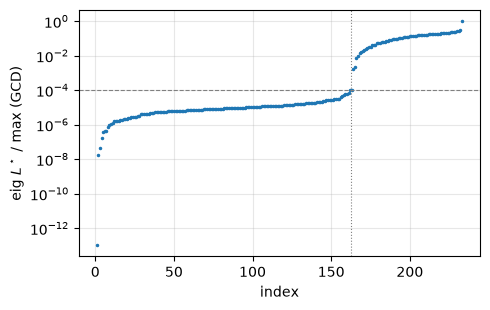

In [6]:
kerTol = 1e-4
lamGCD, UGCD = np.linalg.eigh(Msym(Qgcd._get_total_A(Qgcd.current_lags)))
N = UGCD[:, lamGCD < kerTol*lamGCD[-1]]
K = N.shape[1]
xs = Qgcd.current_xstar
xr = xs - N @ (N.conj().T @ xs)
print(f"eps {kerTol:.0e}: kernel dimension {K} of {Ndes}, largest kernel eigenvalue / max {lamGCD[K - 1]/lamGCD[-1]:.1e}, "
      f"next {lamGCD[K]/lamGCD[-1]:.1e}")

def lagrangianRatio(x):
    # scattering Lagrangian D - (x - x*)^H L* (x - x*), relative to D
    e = x - xs
    return 1 - np.real(e.conj() @ Msym(Qgcd._get_total_A(Qgcd.current_lags)) @ e)/Qgcd.current_dual

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(np.arange(1, Ndes + 1), lamGCD/lamGCD[-1], '.', ms=3)
ax.axhline(kerTol, ls='--', c='gray', lw=0.8); ax.axvline(K + 0.5, ls=':', c='gray', lw=0.8)
ax.set_xlabel('index'); ax.set_ylabel(r'eig $L^\star$ / max (GCD)'); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## IRLS in the kernel

`shiftForm` maps a quadratic $-x^H A x + 2\operatorname{Re}(x^H s) + c$ of the full variable to $y$. In the scattered voltage,
$\sum_i \alpha_i |I_i|^2 = x^H W^H \operatorname{diag}(\alpha) W x$, and
$\sum_i \beta_i |r_i|^2 = x^H C^H \operatorname{diag}(\beta) C x + 2\operatorname{Re}(x^H C^H \operatorname{diag}(\beta) V) + \sum_i \beta_i |V_i|^2$ with
$C = Z_\mathrm{tot} W$. The objective of each step is scaled by its value at the current iterate, so the dual stays of order one.

Each step maximizes $-f$, so $A_0 \succ 0$ and $\lambda = 0$ is dual feasible. With two constraints the QCQP is strongly dual, and its dual
current is the step's minimizer. The multipliers are carried over between steps (`solveReduced` scales them toward zero when needed).

In [7]:
def shiftForm(A, s, c, x0, N):
    # f(x0 + N y) in the same form, in y
    Ax0 = A @ x0
    return Msym(N.conj().T @ A @ N), N.conj().T @ (s - Ax0), float(np.real(-x0.conj() @ Ax0 + 2*x0.conj() @ s) + c)

def generalQCQP(objective, cons):
    # QCQP with only general constraints (A2 = 1), objective (A0, s0, c0) and constraints [(B_j, s_2j, c_2j)]
    A0r, s0r, c0r = objective
    K = len(s0r)
    return DenseSharedProjQCQP(A0r, s0r, c0r, np.eye(K, dtype=complex), np.zeros(K, dtype=complex), [], Pstruct=sp.eye(K),
                               B_j=[c[0] for c in cons], s_2j=[c[1] for c in cons], c_2j=np.array([c[2] for c in cons]), verbose=0)

def setLags(Q, lags):
    Q.current_lags = lags
    Q.current_dual = Q.get_dual(lags)[0]
    Q.current_xstar = Q._get_xstar(lags)[0]

class EvalCap(Exception):
    pass

def solveReduced(Qr, lags, maxEval=3000):
    # start from (1 + t) lags, the smallest |t| in the list that is strictly dual feasible (t < 0 shrinks toward lambda = 0, feasible for A0 > 0). The optimizer has no iteration limit and a
    # reduced dual can be unbounded below (infeasible restricted primal, see Kernel GCD), so get_dual is capped at maxEval calls and
    # the multipliers with the lowest unpenalized dual seen are kept. Returns t and whether the cap was hit.
    t = next(t for t in [1e-6, -1e-6, 1e-4, -1e-4, 1e-2, -1e-2, 0.1, -0.1, 1.0, -0.5, 10.0, -1.0] if Qr.is_dual_feasible((1 + t)*lags))
    l0 = (1 + t)*lags
    best = [Qr.get_dual(l0)[0], l0.copy()]
    count = [0]
    getDual = Qr.get_dual
    def cappedDual(l, *args, **kwargs):
        count[0] += 1
        if count[0] > maxEval:
            raise EvalCap
        out = getDual(l, *args, **kwargs)
        D = out[0] if not kwargs.get("penalty_vectors") else getDual(l)[0]
        if D < best[0]:
            best[0], best[1] = D, np.array(l, dtype=float).copy()
        return out
    Qr.get_dual = cappedDual
    capped = False
    try:
        Qr.solve_current_dual_problem(method='newton', init_lags=l0, opt_params=opt_params)
    except EvalCap:
        capped = True
    finally:
        del Qr.get_dual
    if capped or Qr.current_dual > best[0]:
        setLags(Qr, best[1])
    return t, capped

def projectorForm(p, a, B):
    # diagonal projector constraint Re(-x^H A1 P A2 x + 2 x^H A2^H P^H s1) at x = a + B y, as a general constraint in y
    return shiftForm(Msym(A1 @ (p[:, None]*A2)), A2.conj().T @ (np.conj(p)*s1), 0.0, a, B)

In [8]:
C = Ztot @ W # r = V + C x
pGlob = [np.ones(Ndes, dtype=complex), 1j*np.ones(Ndes, dtype=complex)]
consGlob = [projectorForm(p, xr, N) for p in pGlob] # global power constraints in y

def currents(x):
    I = VtoI(x)
    return I, Vinc - Ztot @ I

def irlsObjective(alpha, beta):
    # f(x) = sum alpha |I|^2 + beta |r|^2 as (A, s, c) of -f, in y
    A = WH @ (alpha[:, None]*W)
    s = np.zeros(Ndes, dtype=complex)
    c0 = 0.0
    if beta is not None:
        A = A + C.conj().T @ (beta[:, None]*C)
        s = -C.conj().T @ (beta*Vinc)
        c0 = -np.sum(beta*np.abs(Vinc)**2)
    return shiftForm(Msym(A), s, c0, xr, N)

def structureStats(x):
    I, r = currents(x)
    d = complexDensity(I)
    return dict(P=evalObj(I)/Qgcd.current_dual, Lag=lagrangianRatio(x),
                cGlob=np.linalg.norm(constraintRes(Qglob, x))/Qgcd.current_dual,
                zeroI=int(np.count_nonzero(np.abs(I) < 1e-3*np.abs(I).max())),
                metal=int(np.count_nonzero(np.abs(d - 1) < 0.1)),
                w=np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc),
                wSum=np.sum(np.abs(localViolation(I)))/np.abs(I.conj() @ Vinc))

def complexDensity(I):
    u = Vinc - Ztot @ I + Zs*Ldiag*I
    return Zs*Ldiag*I/u

def irls(complementarity, nIter=25, delta0=1.0, deltaMin=1e-3, rate=0.7):
    I0, r0 = currents(xs)
    sI, sr = np.sqrt(np.mean(np.abs(I0)**2)), np.sqrt(np.mean(np.abs(r0)**2)) # smoothing scales
    x, lags, hist = xs.copy(), np.zeros(2), [dict(it=0, **structureStats(xs))]
    for it in range(1, nIter + 1):
        delta = max(delta0*rate**(it - 1), deltaMin)
        I, r = currents(x)
        alpha = 1/(np.abs(I)**2 + (delta*sI)**2)
        beta = 1/(np.abs(r)**2 + (delta*sr)**2) if complementarity else None
        A0, s0, c0 = irlsObjective(alpha, beta)
        y = N.conj().T @ (x - xr)
        scale = np.real(y.conj() @ A0 @ y - 2*y.conj() @ s0) - c0 # f at the current iterate
        Q = generalQCQP((A0/scale, s0/scale, c0/scale), consGlob)
        t, capped = solveReduced(Q, lags)
        lags = Q.current_lags.copy()
        x = xr + N @ Q.current_xstar
        f = np.real(Q.current_xstar.conj() @ A0 @ Q.current_xstar - 2*Q.current_xstar.conj() @ s0) - c0
        hist.append(dict(it=it, delta=delta, bound=-Q.current_dual*scale/f, capped=capped, **structureStats(x)))
    return x, hist

def irlsReport(name, hist):
    print(name)
    for h in hist:
        step = "" if h["it"] == 0 else f"delta {h['delta']:.1e}, f bound / f(y*) {h['bound']:.6f}{' (capped)' if h['capped'] else ''}, "
        print(f"  it {h['it']:2d}: {step}P/D {h['P']:.4f}, Lagrangian/D {h['Lag']:.4f}, ||c_global||/D {h['cGlob']:.1e}, "
              f"|I_i| < 1e-3 max: {h['zeroI']:3d}, |d_i - 1| < 0.1: {h['metal']:3d}, max|w_i|/|I^H V| {h['w']:.1e}, sum|w_i|/|I^H V| {h['wSum']:.1e}")

results = {}
for name, comp in [("sparsity", False), ("complementarity", True)]:
    t1 = time.time()
    results[name] = irls(comp)
    irlsReport(f"{name} ({time.time() - t1:.0f}s)", results[name][1])

sparsity (2s)
  it  0: P/D 1.0000, Lagrangian/D 1.0000, ||c_global||/D 2.2e+02, |I_i| < 1e-3 max:   0, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 4.5e+01, sum|w_i|/|I^H V| 8.9e+02
  it  1: delta 1.0e+00, f bound / f(y*) 1.000000, P/D 0.9977, Lagrangian/D 0.9675, ||c_global||/D 1.3e-05, |I_i| < 1e-3 max:   1, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 6.6e+01, sum|w_i|/|I^H V| 1.3e+03
  it  2: delta 7.0e-01, f bound / f(y*) 1.000000, P/D 0.9977, Lagrangian/D 0.9732, ||c_global||/D 1.1e-06, |I_i| < 1e-3 max:   0, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 6.2e+01, sum|w_i|/|I^H V| 1.3e+03
  it  3: delta 4.9e-01, f bound / f(y*) 1.000000, P/D 0.9975, Lagrangian/D 0.9763, ||c_global||/D 5.7e-07, |I_i| < 1e-3 max:   0, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 5.4e+01, sum|w_i|/|I^H V| 1.3e+03
  it  4: delta 3.4e-01, f bound / f(y*) 1.000000, P/D 0.9973, Lagrangian/D 0.9779, ||c_global||/D 1.2e-05, |I_i| < 1e-3 max:   0, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 4.6e+01, sum|w_i|/|I^H V| 1.3e+03
  it  5: del

complementarity (2s)
  it  0: P/D 1.0000, Lagrangian/D 1.0000, ||c_global||/D 2.2e+02, |I_i| < 1e-3 max:   0, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 4.5e+01, sum|w_i|/|I^H V| 8.9e+02
  it  1: delta 1.0e+00, f bound / f(y*) 1.000000, P/D 0.9978, Lagrangian/D 0.9956, ||c_global||/D 2.2e-06, |I_i| < 1e-3 max:   2, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 9.6e+01, sum|w_i|/|I^H V| 4.8e+02
  it  2: delta 7.0e-01, f bound / f(y*) 1.000000, P/D 0.9971, Lagrangian/D 0.9955, ||c_global||/D 7.6e-05, |I_i| < 1e-3 max:   0, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 1.6e+02, sum|w_i|/|I^H V| 5.0e+02
  it  3: delta 4.9e-01, f bound / f(y*) 1.000000, P/D 0.9970, Lagrangian/D 0.9954, ||c_global||/D 4.1e-05, |I_i| < 1e-3 max:   0, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 1.8e+02, sum|w_i|/|I^H V| 5.0e+02
  it  4: delta 3.4e-01, f bound / f(y*) 1.000000, P/D 0.9970, Lagrangian/D 0.9952, ||c_global||/D 3.9e-07, |I_i| < 1e-3 max:   0, |d_i - 1| < 0.1:   0, max|w_i|/|I^H V| 1.8e+02, sum|w_i|/|I^H V| 4.9e+02
  it 

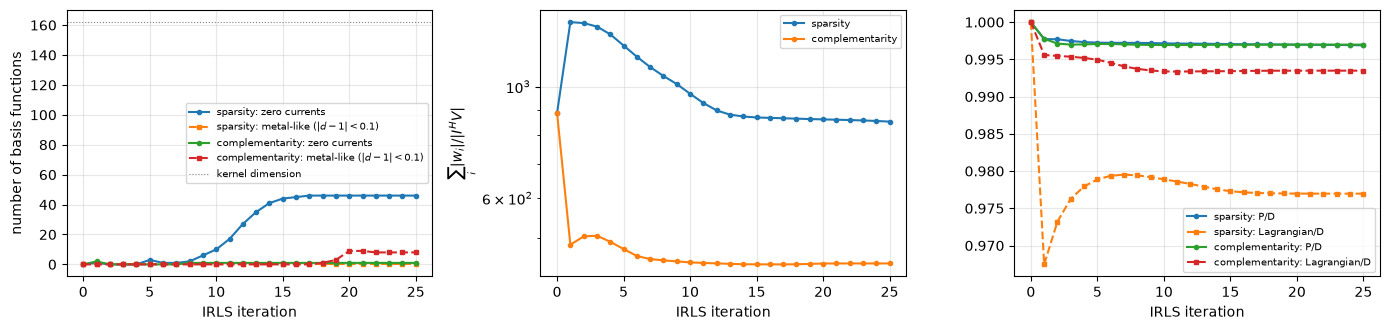

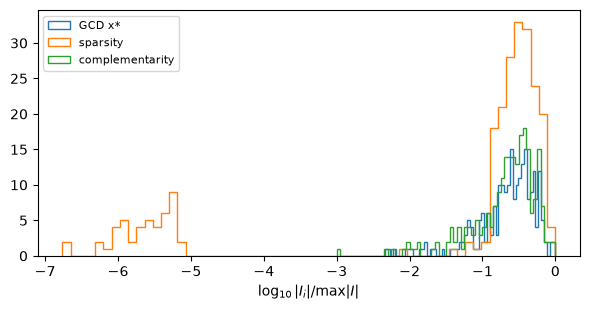

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for name, (x, hist) in results.items():
    it = [h["it"] for h in hist]
    axes[0].plot(it, [h["zeroI"] for h in hist], 'o-', ms=3, label=f"{name}: zero currents")
    axes[0].plot(it, [h["metal"] for h in hist], 's--', ms=3, label=f"{name}: metal-like ($|d - 1| < 0.1$)")
    axes[1].semilogy(it, [h["wSum"] for h in hist], 'o-', ms=3, label=name)
    axes[2].plot(it, [h["P"] for h in hist], 'o-', ms=3, label=f"{name}: P/D")
    axes[2].plot(it, [h["Lag"] for h in hist], 's--', ms=3, label=f"{name}: Lagrangian/D")
axes[0].axhline(K, c='gray', ls=':', lw=0.8, label='kernel dimension')
axes[0].set_xlabel('IRLS iteration'); axes[0].set_ylabel('number of basis functions'); axes[0].legend(fontsize=7)
axes[1].set_xlabel('IRLS iteration'); axes[1].set_ylabel(r'$\sum_i |w_i| / |I^H V|$'); axes[1].legend(fontsize=7)
axes[2].set_xlabel('IRLS iteration'); axes[2].legend(fontsize=7)
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.2))
for name, x in [("GCD x*", xs)] + [(n, r[0]) for n, r in results.items()]:
    I = VtoI(x)
    ax.hist(np.log10(np.abs(I)/np.abs(I).max()), bins=60, histtype='step', label=name)
ax.set_xlabel(r'$\log_{10}|I_i| / \max|I|$'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Pointwise inference and the complex material density

As in `nullSpaceMinField.ipynb`. The complex density $d_i = Z_s L_{ii} I_i / u_i$, with $u = V - Z_\mathrm{tot} I + Z_s L_{ii} I$, is 1 on metal and 0 where the
basis function is removed. The pointwise fits project it:
- the admittance form takes $\operatorname{clip}(\operatorname{Re} d, 0, 1)$;
- the impedance form projects the series impedance onto the passive ray.

The binary design with the largest scattered power over the rounding thresholds is kept.

In [10]:
dMin = 1e-6 # basis functions with d_i < dMin are removed in the realized structure
thsLog = np.logspace(-6, 0, 61)[:-1] # thresholds for binary rounding of d

def inferDimp(I):
    # impedance form: series impedance projected onto the passive ray, d = 1/(1 + t)
    nz = I != 0
    r = np.zeros(Ndes, dtype=complex)
    r[nz] = (Vinc - Ztot @ I)[nz]/I[nz]
    t = np.maximum(0, np.real(np.conj(Zs)*r)/(np.abs(Zs)**2*Ldiag))
    return np.where(nz, 1/(1 + t), 0.0)

def inferDadm(I):
    # admittance form: real part of the complex density, clipped
    return np.clip(complexDensity(I).real, 0, 1)

def realizedCurrent(d):
    # (Ztot + diag(Zs Lii (1/d - 1))) I = V on the kept basis functions, I = 0 elsewhere
    keep = d >= dMin
    I = np.zeros(Ndes, dtype=complex)
    Zd = Ztot + np.diag(Zs*Ldiag*(1/np.maximum(d, dMin) - 1))
    I[keep] = np.linalg.solve(Zd[np.ix_(keep, keep)], Vinc[keep])
    return I

def bestBinary(d):
    designs = [d > t for t in thsLog]
    Is = [realizedCurrent(k.astype(float)) for k in designs]
    Pb = np.array([evalObj(I) for I in Is])
    k = int(np.argmax(Pb))
    return dict(keep=designs[k], I=Is[k], P=Pb[k], th=thsLog[k])

print(f"full plate: max |d - 1| = {np.abs(complexDensity(Ifull) - 1).max():.1e}")
final = {"GCD x* (reference)": xs, **{f"{n} IRLS": r[0] for n, r in results.items()}}
inference = {}
for name, x in final.items():
    I = VtoI(x)
    d = complexDensity(I)
    inference[name] = dict(d=d, **{form: bestBinary(infer(I)) for form, infer in [("impedance form", inferDimp), ("admittance form", inferDadm)]})
    print(f"{name:20s}: |d| quantiles 50/90/max " + "/".join(f"{q:.1e}" for q in np.quantile(np.abs(d), [0.5, 0.9, 1.0]))
          + f", |d - 1| < 0.1: {np.count_nonzero(np.abs(d - 1) < 0.1):3d}, "
          + ", ".join(f"{form} P/D {inference[name][form]['P']/Qgcd.current_dual:.4f} ({inference[name][form]['P']:.3e} W, kept {inference[name][form]['keep'].sum()})"
                      for form in ["impedance form", "admittance form"]))

full plate: max |d - 1| = 1.2e-09
GCD x* (reference)  : |d| quantiles 50/90/max 1.3e-04/6.3e-04/3.5e-03, |d - 1| < 0.1:   0, impedance form P/D 0.0045 (7.908e-02 W, kept 176), admittance form P/D 0.0001 (1.982e-03 W, kept 106)
sparsity IRLS       : |d| quantiles 50/90/max 9.2e-05/6.7e-04/4.9e-02, |d - 1| < 0.1:   0, impedance form P/D 0.0059 (1.049e-01 W, kept 153), admittance form P/D 0.0001 (9.959e-04 W, kept 79)
complementarity IRLS: |d| quantiles 50/90/max 5.2e-01/1.3e+00/3.0e+00, |d - 1| < 0.1:   8, impedance form P/D 0.0070 (1.241e-01 W, kept 162), admittance form P/D 0.0016 (2.815e-02 W, kept 153)


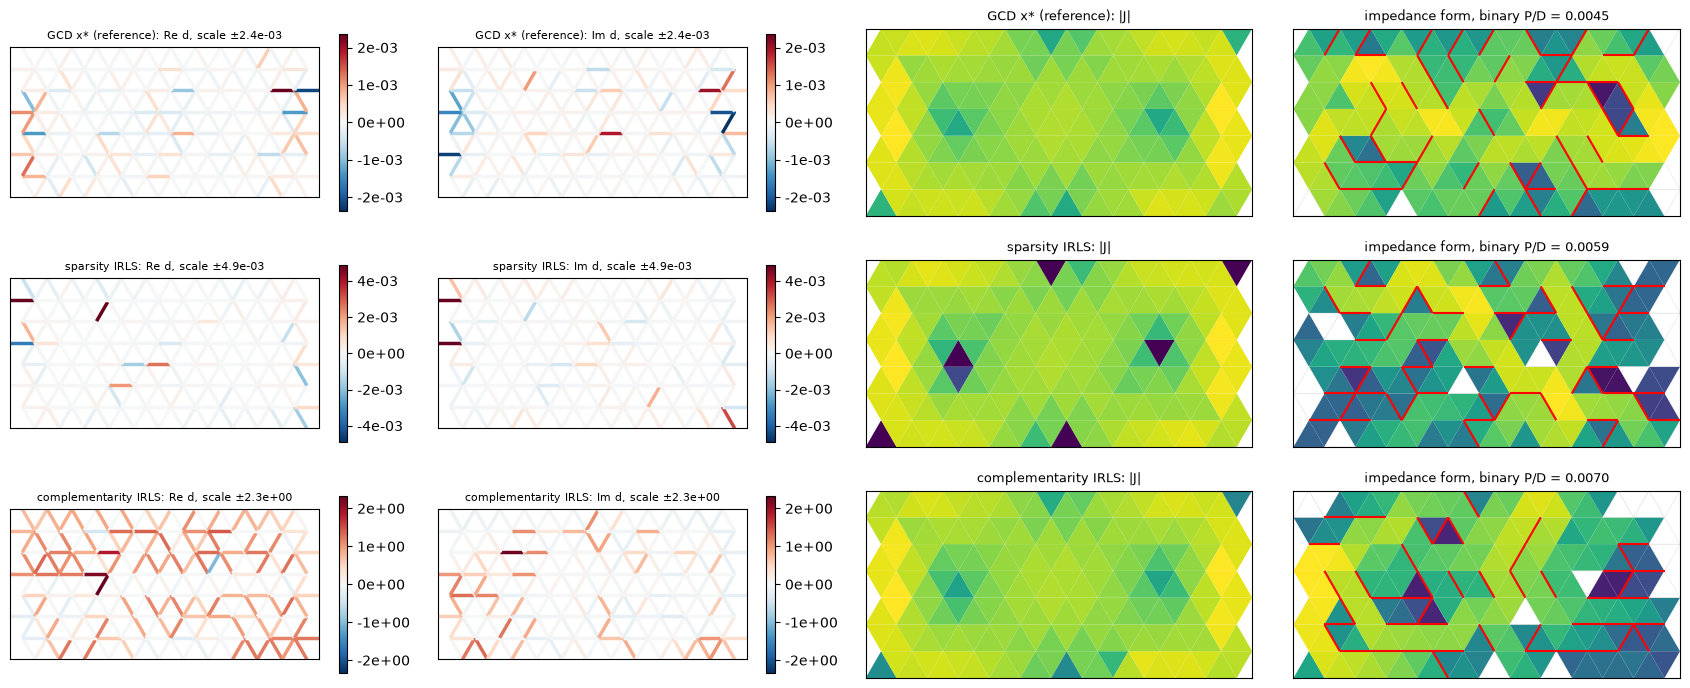

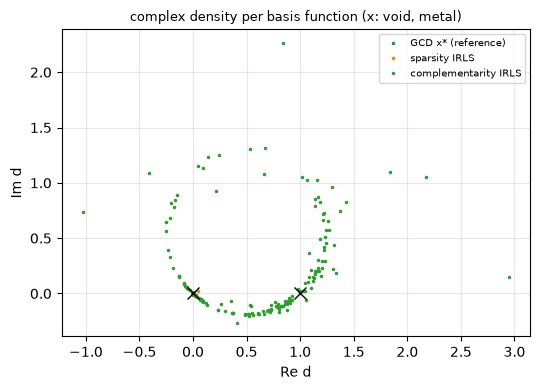

In [11]:
names = list(inference)
fig, axes = plt.subplots(len(names), 4, figsize=(17, 2.4*len(names)))
for row, name in zip(axes, names):
    r = inference[name]
    plotComplexDensity(row[:2], r["d"], name)
    plotStructure(row[2], np.ones(Ndes, dtype=bool), VtoI(final[name]), f"{name}: |J|")
    form = max(["impedance form", "admittance form"], key=lambda f: r[f]["P"])
    plotStructure(row[3], r[form]["keep"], r[form]["I"], f"{form}, binary P/D = {r[form]['P']/Qgcd.current_dual:.4f}")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4))
for name in names:
    d = inference[name]["d"]
    ax.plot(d.real, d.imag, '.', ms=3, label=name)
ax.plot([0, 1], [0, 0], 'kx', ms=8)
ax.set_xlabel('Re d'); ax.set_ylabel('Im d'); ax.legend(fontsize=7); ax.set_title('complex density per basis function (x: void, metal)', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## Conclusions

These are the numbers of one run. GCD is not exactly reproducible; the phase statistics below come from a second run and agree qualitatively.

**Kernel.** At $\epsilon = 10^{-4}$ the GCD near-kernel has dimension 162 of 233. The GCD dual current $x^\star$ violates the global power balance
by $220\,D$ and has no zero current. Every IRLS step is strongly dual: the bound on the weighted objective equals its value at the step's
minimizer to $10^{-6}$, and the power balance holds to $\|c\|/D \leq 4\times10^{-4}$.

**Cost in the scattering Lagrangian.** The IRLS moves far into the subspace, so the Lagrangian drops more than for the minimal field (0.5 %):
2.3 % for sparsity and 0.65 % for complementarity. In both cases $P/D = 0.997$.

**Sparsity.** IRLS on $\sum \log(|I_i|^2 + \delta^2)$ switches off 46 basis functions ($|I_i| < 10^{-3}\max|I|$). That is far fewer than the kernel
dimension allows, because the two power constraints and the image part $x_r$ fix the rest. The pointwise violation barely changes
($\sum|w_i|$ by 4 %), and no basis function becomes metal-like: $|d| \lesssim 5\times10^{-2}$.

**Complementarity.** IRLS on $\sum \log(|I_i|^2 + \delta^2) + \log(|r_i|^2 + \delta^2)$ halves the summed pointwise violation and, for the first time,
brings the complex density to order one: median $|d| = 0.5$, with 8 basis functions within 0.1 of metal. The density lies on a circle through 0
and 1 (centre about $0.5 + 0.4j$). That is the image of a purely reactive series load, $d = 1/(1 + jX/(Z_s L_{ii}))$. The inferred series impedance
$r_i/I_i$ is almost purely reactive (median $|\operatorname{Im}/\operatorname{Re}| = 8$), split into inductive ($+85°$ to $+94°$) and capacitive
($-95°$ to $-107°$) edges. The kernel current is therefore consistent with a plate loaded by lumped reactances, a tuned resonator, rather than with
a void/metal pattern.

**Inference.** The pointwise fits project onto passive loss ($d \in [0, 1]$) and discard the reactance:
- complementarity current: 0.7 % of the bound (0.12 W);
- sparsity current: 0.6 %;
- GCD $x^\star$: 0.45 %.

So the kernel can make the current locally consistent with *some* surface impedance, but that impedance is reactive. Reaching void/metal would
need either a constraint that forbids reactive loads, such as a fixed $Q_W$ or the conductivity reduction of `main.tex`, or an inference that
maps reactive loads onto slots and strips.